# Los cálculos del Caso 8, paso a paso

Este cuaderno muestra **cómo sale cada número** que reportamos: el retorno, la volatilidad,
las alertas, las correlaciones con el clima, los quiebres y el pronóstico.

**El código no vive aquí.** Vive en la carpeta `src/indicators/`; el cuaderno solo lo importa
y lo muestra funcionando sobre los datos reales. Así hay una sola versión de cada cálculo.

| Capítulo | Qué calcula | Archivo |
|---|---|---|
| 1 | Retorno mensual | `src/indicators/volatilidad.py` |
| 2 | Volatilidad | `src/indicators/volatilidad.py` |
| 3 | Z-score y alertas (el semáforo) | `src/indicators/volatilidad.py` |
| 4 | Correlación con la lluvia, con rezago | `src/indicators/vigilancia.py` |
| 5 | Efecto del clima, eslabón por eslabón | `src/indicators/sensibilidad.py` |
| 6 | Quiebres (prueba de Chow) | `src/indicators/quiebres.py` |
| 7 | Pronóstico del precio | `src/indicators/pronostico.py` |
| 8 | Dependencia de importaciones | `src/indicators/volatilidad.py` |
| 9 | De dónde sale cada cifra reportada | — |
| 10 | Comprobación: el cuaderno reproduce la base | — |

Cada capítulo sigue el mismo orden: **para qué sirve → la fórmula → un ejemplo a mano →
la función real → una gráfica → cómo se lee y qué límite tiene.**

**Cómo correrlo** (desde la raíz del proyecto, sin internet):

```
.venv\Scripts\python.exe -m jupyter notebook notebooks\calculos_paso_a_paso.ipynb
```

Las tablas que se leen están descritas en `docs/diccionario_datos.md`.

In [1]:
import sys
from pathlib import Path

# La raiz del proyecto es la carpeta que contiene `src`, se abra el cuaderno desde donde se abra.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.indicators import pronostico, quiebres, sensibilidad, vigilancia, volatilidad

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
VERDE, AMARILLO, ROJO, AZUL, GRIS = "#2e9e5b", "#e0a800", "#d64545", "#2f6fb0", "#8a8f98"

# Solo lectura: el cuaderno nunca modifica la base.
con = duckdb.connect(str(RAIZ / "data" / "processed" / "caso8.duckdb"), read_only=True)
precios = con.execute("SELECT * FROM col_precio_mayorista_mensual").df()

def fecha(periodo):
    # 202503 -> fecha del 1 de marzo de 2025, para el eje de las graficas
    return pd.to_datetime(pd.Series(periodo).astype(int).astype(str), format="%Y%m").to_numpy()

print(f"{len(precios):,} precios mensuales | {precios['producto'].nunique()} productos | "
      f"{precios['mercado'].nunique()} mercados | de {precios['periodo'].min()} a {precios['periodo'].max()}")

34,454 precios mensuales | 33 productos | 20 mercados | de 202002 a 202610


**El ejemplo que acompaña todo el cuaderno** es el limón Tahití en Bogotá: es la serie que
citamos en la presentación (va de 698 a 6.075 pesos el kilo en tres meses).

In [2]:
PRODUCTO, MERCADO = "Limón Tahití", "BOGOTÁ, D.C."
ejemplo = (precios[(precios["producto"] == PRODUCTO) & (precios["mercado"] == MERCADO)]
           .sort_values("periodo").reset_index(drop=True))
ejemplo[["periodo", "precio_cop_kg", "precio_min", "precio_max", "dias_con_dato", "mes_cerrado"]].tail(6)

,periodo,precio_cop_kg,precio_min,precio_max,dias_con_dato,mes_cerrado
62,202605,"2,847.330",2196,3446,21,True
63,202606,"2,168.450",1554,3071,22,True
64,202607,"2,022.390",1571,2429,23,True
65,202608,"2,547.950",1893,3649,20,True
66,202609,"2,938.360",2143,3857,22,True
67,202610,"3,434.570",3161,3786,7,False


---
## 1. Retorno mensual

**Para qué sirve.** Dice cuánto cambió el precio de un mes al siguiente. Es la materia prima
de todo lo demás: la volatilidad y las alertas se calculan sobre retornos, no sobre precios.

**La fórmula.**

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

- $P_t$: precio de este mes · $P_{t-1}$: precio del mes anterior · $\ln$: logaritmo natural.

**Por qué logaritmo y no porcentaje.** Si un precio sube 50 % y luego baja 33 %, vuelve
exactamente a donde estaba, pero +50 y −33 no suman cero. En logaritmos sí:

In [3]:
print(f"En porcentaje: +50 % y -33,3 %  -> suma {50 - 33.33:+.1f}   (parece que subio)")
print(f"En logaritmo : {np.log(1.5):+.3f} y {np.log(1 / 1.5):+.3f} -> suma {np.log(1.5) + np.log(1 / 1.5):+.3f} (correcto: quedo igual)")

En porcentaje: +50 % y -33,3 %  -> suma +16.7   (parece que subio)
En logaritmo : +0.405 y -0.405 -> suma -0.000 (correcto: quedo igual)


**A mano**, con seis meses reales del limón Tahití en Bogotá:

In [4]:
mano = ejemplo.loc[ejemplo["periodo"].between(202301, 202306), ["periodo", "precio_cop_kg"]].copy()
mano["precio_mes_anterior"] = mano["precio_cop_kg"].shift(1)
mano["cambio_pct"] = (mano["precio_cop_kg"] / mano["precio_mes_anterior"] - 1) * 100
mano["retorno_log"] = np.log(mano["precio_cop_kg"] / mano["precio_mes_anterior"])
mano

,periodo,precio_cop_kg,precio_mes_anterior,cambio_pct,retorno_log
22,202301,"2,629.100",NaN,NaN,NaN
23,202302,"4,043.150","2,629.100",53.785,0.430
24,202303,"6,074.830","4,043.150",50.250,0.407
25,202304,"4,737.780","6,074.830",-22.010,-0.249
26,202305,"1,642.130","4,737.780",-65.340,-1.060
27,202306,698.090,"1,642.130",-57.489,-0.855


**La función real** es `volatilidad.retornos()`. Da lo mismo que la cuenta a mano:

In [5]:
con_retorno = volatilidad.retornos(precios)
ej = con_retorno[(con_retorno["producto"] == PRODUCTO) & (con_retorno["mercado"] == MERCADO)].reset_index(drop=True)

funcion = ej.loc[ej["periodo"].between(202302, 202306), "retorno_log"].to_numpy()
assert np.allclose(funcion, mano["retorno_log"].dropna().to_numpy())
print("La funcion y la cuenta a mano coinciden.")
ej.loc[ej["periodo"].between(202301, 202306), ["periodo", "precio_cop_kg", "retorno_log", "meses_desde_anterior"]]

La funcion y la cuenta a mano coinciden.


,periodo,precio_cop_kg,retorno_log,meses_desde_anterior
22,202301,"2,629.100",0.273,1.000
23,202302,"4,043.150",0.430,1.000
24,202303,"6,074.830",0.407,1.000
25,202304,"4,737.780",-0.249,1.000
26,202305,"1,642.130",-1.060,1.000
27,202306,698.090,-0.855,1.000


**El hueco de 2021.** SIPSA no publicó datos de enero de 2021 a enero de 2022. Comparar
diciembre de 2020 con febrero de 2022 no es un cambio "de un mes", así que la función deja
ese retorno vacío en vez de inventarlo:

In [6]:
ej.loc[ej["periodo"].between(202010, 202204), ["periodo", "precio_cop_kg", "meses_desde_anterior", "retorno_log"]]

,periodo,precio_cop_kg,meses_desde_anterior,retorno_log
8,202010,"1,413.900",1.000,0.008
9,202011,"1,496.160",1.000,0.057
10,202012,"1,186.940",1.000,-0.232
11,202202,"4,261.500",14.000,NaN
12,202203,"5,481.790",1.000,0.252
13,202204,"5,655.240",1.000,0.031


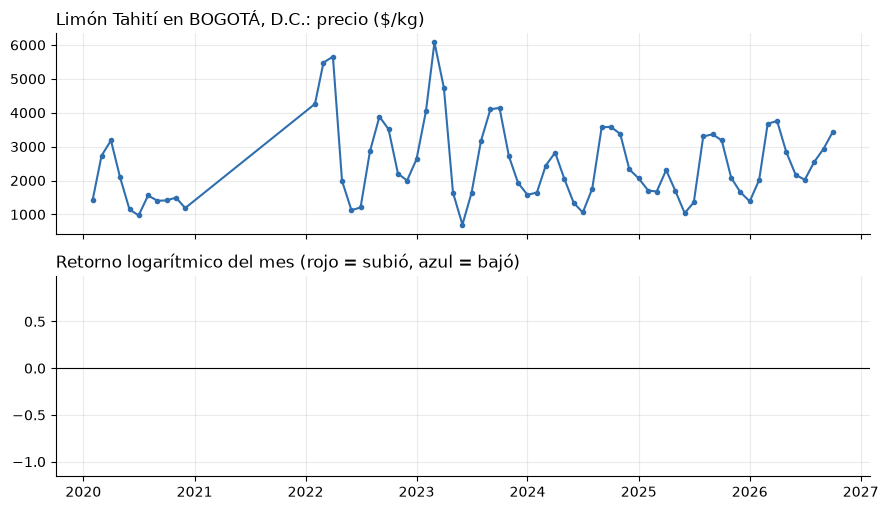

In [7]:
fig, (a, b) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
a.plot(fecha(ej["periodo"]), ej["precio_cop_kg"], color=AZUL, marker="o", ms=3)
a.set_title(f"{PRODUCTO} en {MERCADO}: precio ($/kg)", loc="left")
b.bar(fecha(ej["periodo"]), ej["retorno_log"], width=20,
      color=np.where(ej["retorno_log"] > 0, ROJO, AZUL))
b.axhline(0, color="black", lw=0.8)
b.set_title("Retorno logarítmico del mes (rojo = subió, azul = bajó)", loc="left")
fig.tight_layout()

**Cómo se lee.** Un retorno de +0,30 es una subida de cerca del 35 %; uno de −0,30, una
bajada de cerca del 26 %. Para cambios pequeños, el retorno × 100 es casi el porcentaje.

**Límite.** Solo hay retorno entre dos meses seguidos con precio. Los huecos se quedan huecos.

---
## 2. Volatilidad

**Para qué sirve.** Mide qué tan brusco se mueve un precio. Un producto con volatilidad alta
tiene precios impredecibles; uno con volatilidad baja es estable.

**La fórmula.** Es la desviación estándar de los retornos de los últimos 12 meses:

$$\sigma_t = \text{desviación estándar}(r_{t-11}, \dots, r_t) \qquad\qquad \sigma_{\text{anual}} = \sigma_t \times \sqrt{12}$$

- Se usan 12 meses porque así entra un ciclo completo de cosechas.
- Se multiplica por $\sqrt{12}$ para expresarla "por año", que es como se publica la
  volatilidad de cualquier otro precio y permite comparar.
- Con menos de 6 retornos en la ventana no se calcula: sería ruido.

**A mano**, para diciembre de 2023:

In [8]:
ultimos_12 = ej.loc[ej["periodo"] <= 202312, "retorno_log"].tail(12)
sigma = ultimos_12.std()
print(f"Los 12 retornos: {ultimos_12.round(3).tolist()}")
print(f"Desviacion estandar (volatilidad mensual): {sigma:.4f}")
print(f"Anualizada (x raiz de 12):                 {sigma * np.sqrt(12):.4f}  = {sigma * np.sqrt(12) * 100:.1f} %")

Los 12 retornos: [0.273, 0.43, 0.407, -0.249, -1.06, -0.855, 0.851, 0.661, 0.259, 0.01, -0.424, -0.34]
Desviacion estandar (volatilidad mensual): 0.5928
Anualizada (x raiz de 12):                 2.0535  = 205.3 %


In [9]:
con_vol = volatilidad.volatilidad(precios)
ej = con_vol[(con_vol["producto"] == PRODUCTO) & (con_vol["mercado"] == MERCADO)].reset_index(drop=True)
fila = ej[ej["periodo"] == 202312].iloc[0]
assert np.isclose(fila["volatilidad"], sigma)
print(f"volatilidad.volatilidad() da {fila['volatilidad']:.4f} mensual y {fila['volatilidad_anualizada']:.4f} anual: coincide.")

volatilidad.volatilidad() da 0.5928 mensual y 2.0535 anual: coincide.


**Todos los productos**, con `volatilidad.resumen_por_producto()`. De aquí sale el ranking de la app:

,producto,mercados,meses,volatilidad_mediana,alertas_rojas,alertas_amarillas,precio_ultimo
13,Limón Tahití,16,68,1.352,0,17,"3,600.000"
16,Mango tommy,17,68,1.346,0,18,"9,425.000"
23,Pepino cohombro,20,68,1.169,0,62,"2,787.500"
11,Habichuela,20,68,1.071,0,27,"4,354.500"
12,Limón Común,17,68,0.976,0,22,"4,350.000"


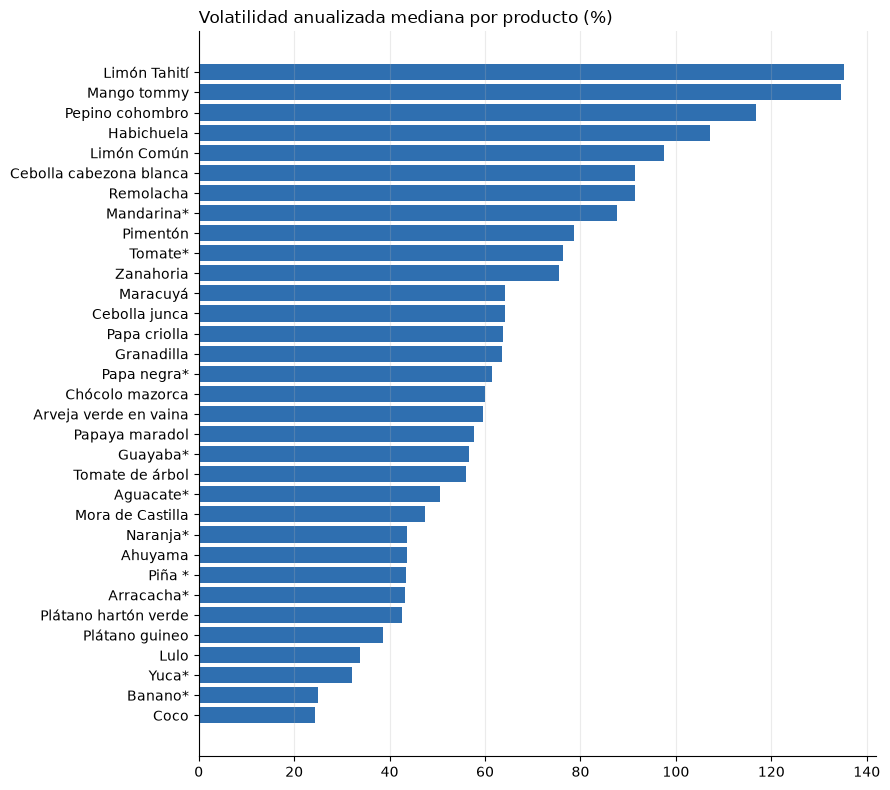

In [10]:
resumen = volatilidad.resumen_por_producto(precios)
orden = resumen.sort_values("volatilidad_mediana")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(orden["producto"], orden["volatilidad_mediana"] * 100, color=AZUL)
ax.set_title("Volatilidad anualizada mediana por producto (%)", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
resumen.head(5)

**Cómo se lee.** 135 % anual no significa que el precio suba 135 %: significa que sus
movimientos mensuales son tan amplios que, sostenidos un año, equivaldrían a esa dispersión.
Sirve para **comparar** productos entre sí.

**Límite.** La ventana cuenta los últimos 12 registros de la serie. Donde está el hueco de
2021, la ventana tiene menos retornos y la cifra es menos firme.

---
## 3. Z-score y alertas: el semáforo

**Para qué sirve.** Responde la pregunta central del proyecto: *¿el movimiento de este mes
es normal para este producto en este mercado, o es raro?*

**La fórmula.**

$$z_t = \frac{r_t - \bar{r}}{s}$$

- $r_t$: retorno del mes · $\bar{r}$: promedio de los retornos de esa serie **hasta ese mes** ·
  $s$: su desviación estándar hasta ese mes.
- $z$ dice a cuántas "desviaciones" está el mes de lo habitual.

| Semáforo | Condición | Qué significa |
|---|---|---|
| 🟢 verde | $|z| \le 2$ | Movimiento normal |
| 🟡 amarilla | $2 < |z| \le 3$ | Movimiento poco común: atención |
| 🔴 roja | $|z| > 3$ | Movimiento anormal |

Los umbrales 2 y 3 son una convención de este trabajo, no una norma oficial.

**Sin mirar el futuro.** El promedio y la desviación de cada mes se calculan solo con lo que
se sabía hasta ese mes. Usar toda la serie sería hacer trampa: en marzo de 2023 nadie conocía
los precios de 2025.

**A mano**, para junio de 2023, cuando el limón cayó 57 % en un mes:

In [11]:
hasta_junio = ej.loc[ej["periodo"] <= 202306, "retorno_log"].dropna()
r = hasta_junio.iloc[-1]
z = (r - hasta_junio.mean()) / hasta_junio.std()
print(f"Retorno de junio de 2023:           {r:+.3f}")
print(f"Promedio historico hasta ese mes:   {hasta_junio.mean():+.3f}")
print(f"Desviacion historica hasta ese mes: {hasta_junio.std():.3f}")
print(f"z = ({r:+.3f} - {hasta_junio.mean():+.3f}) / {hasta_junio.std():.3f} = {z:+.2f}")

Retorno de junio de 2023:           -0.855
Promedio historico hasta ese mes:   -0.077
Desviacion historica hasta ese mes: 0.492
z = (-0.855 - -0.077) / 0.492 = -1.58


In [12]:
con_alerta = volatilidad.alertas(precios)
# `alerta` es una categoria de pandas: se pasa a texto para poder filtrar y contar sin sorpresas.
con_alerta["alerta"] = con_alerta["alerta"].astype(str).replace("nan", "sin dato")
ej = con_alerta[(con_alerta["producto"] == PRODUCTO) & (con_alerta["mercado"] == MERCADO)].reset_index(drop=True)
fila = ej[ej["periodo"] == 202306].iloc[0]
assert np.isclose(fila["z_score"], z)
print(f"volatilidad.alertas() da z = {fila['z_score']:+.2f} y alerta '{fila['alerta']}': coincide.")
ej.loc[ej["alerta"].isin(["amarilla", "roja"]), ["periodo", "precio_cop_kg", "retorno_log", "z_score", "alerta", "direccion"]]

volatilidad.alertas() da z = -1.58 y alerta 'verde': coincide.


,periodo,precio_cop_kg,retorno_log,z_score,alerta,direccion
14,202205,"1,989.330",-1.045,-2.182,amarilla,baja
26,202305,"1,642.130",-1.060,-2.134,amarilla,baja


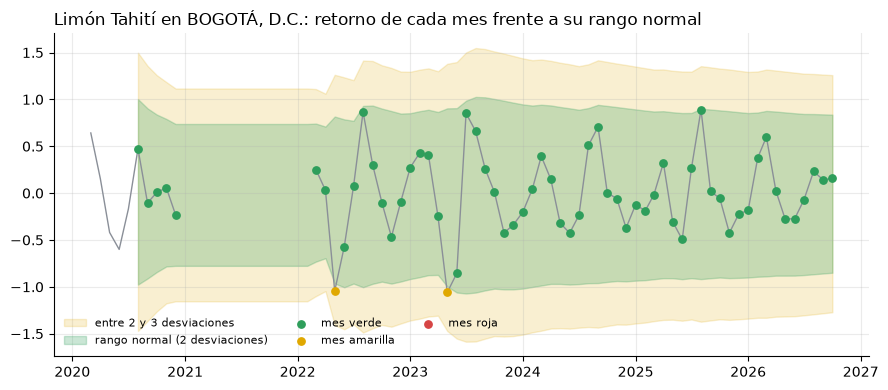

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
x = fecha(ej["periodo"])
ax.fill_between(x, ej["media_hist"] - 3 * ej["desv_hist"], ej["media_hist"] + 3 * ej["desv_hist"],
                color=AMARILLO, alpha=0.18, label="entre 2 y 3 desviaciones")
ax.fill_between(x, ej["media_hist"] - 2 * ej["desv_hist"], ej["media_hist"] + 2 * ej["desv_hist"],
                color=VERDE, alpha=0.25, label="rango normal (2 desviaciones)")
ax.plot(x, ej["retorno_log"], color=GRIS, lw=1)
for nombre, color in (("verde", VERDE), ("amarilla", AMARILLO), ("roja", ROJO)):
    m = (ej["alerta"] == nombre).to_numpy()
    ax.scatter(x[m], ej.loc[m, "retorno_log"], color=color, s=28, zorder=3, label=f"mes {nombre}")
ax.set_title(f"{PRODUCTO} en {MERCADO}: retorno de cada mes frente a su rango normal", loc="left")
ax.legend(ncol=3, fontsize=8, frameon=False, loc="lower left")
fig.tight_layout()

**El semáforo de hoy**: el último mes cerrado, todos los productos y mercados. Esta es la tabla que alimenta la portada de la app.

In [14]:
ultimo_cerrado = int(precios.loc[precios["mes_cerrado"], "periodo"].max())
hoy = con_alerta[con_alerta["periodo"] == ultimo_cerrado]
print(f"Ultimo mes cerrado: {ultimo_cerrado}")
print(hoy["alerta"].value_counts().to_string())
(hoy[hoy["alerta"].isin(["roja", "amarilla"])]
 .sort_values("z_score", key=abs, ascending=False)
 [["producto", "mercado", "precio_cop_kg", "retorno_log", "z_score", "alerta", "direccion"]].head(10))

Ultimo mes cerrado: 202609
alerta
verde       491
amarilla      9
roja          2


,producto,mercado,precio_cop_kg,retorno_log,z_score,alerta,direccion
23847,Chócolo mazorca,POPAYÁN,"1,846.000",0.469,4.263,roja,alza
12637,Plátano hartón verde,IBAGUÉ,"1,843.330",0.332,3.170,roja,alza
24771,Piña *,POPAYÁN,"3,560.000",0.319,2.906,amarilla,alza
24639,Pepino cohombro,POPAYÁN,"1,946.200",0.362,2.863,amarilla,alza
29452,Ahuyama,TUNJA,935.110,0.288,2.748,amarilla,alza
34179,Plátano hartón verde,VILLAVICENCIO,"3,262.220",0.382,2.634,amarilla,alza
26685,Plátano hartón verde,SAN JOSÉ DE CÚCUTA,"3,466.000",0.323,2.548,amarilla,alza
30889,Plátano hartón verde,TUNJA,"2,917.890",0.326,2.513,amarilla,alza
5483,Plátano hartón verde,"BOGOTÁ, D.C.","3,153.000",0.324,2.297,amarilla,alza
6499,Guayaba*,BUCARAMANGA,"1,254.850",-0.697,-2.211,amarilla,baja


**Ojo con el ejemplo de arriba.** El limón cayó 57 % en junio de 2023 y aun así el mes quedó en
verde ($z = -1{,}58$). No es un error: el limón Tahití es tan volátil que una caída así está
dentro de lo que suele hacer. El semáforo compara cada producto **contra su propia historia**.

**Cómo se lee.** Una alerta roja al alza con $z = +3{,}5$ dice: "este mes el precio subió
mucho más de lo que suele moverse este producto aquí". No dice por qué.

**Límites.** (1) Hacen falta al menos 6 retornos previos; antes de eso el mes queda "sin dato",
no en verde. (2) El mes en curso no se usa: todavía le faltan días. (3) Un producto muy volátil
necesita un movimiento enorme para dar alerta, porque se compara contra su propia historia.

---
## 4. Correlación con la lluvia, con rezago

**Para qué sirve.** Busca pistas: *cuando llueve más o menos de lo normal en la zona donde se
cultiva un producto, ¿su precio suele moverse unos meses después?*

**La fórmula.** Coeficiente de correlación de **Spearman** ($\rho$): se ordenan los meses de
menor a mayor por retorno, se ordenan por lluvia, y se mide si los dos órdenes se parecen.

- $\rho = +1$: siempre que una sube, la otra sube · $\rho = -1$: siempre van al revés · $\rho = 0$: sin relación.
- Se usa Spearman y no Pearson porque los precios tienen saltos extremos, y Spearman, al
  trabajar con posiciones y no con valores, no se deja arrastrar por ellos.

**El rezago.** Se compara el precio del mes $t$ con la lluvia del mes $t-k$ (hace $k$ meses).
"Hace $k$ meses" es siempre calendario real: la función `vigilancia.rezagar()` corre las
fechas, no las filas, para no equivocarse en el hueco de 2021.

In [15]:
ret = vigilancia.retornos_nacionales(precios)          # precio nacional = mediana de los mercados
clima = con.execute("SELECT * FROM mundo_clima_zona_mensual").df()
zonas = con.execute("SELECT * FROM catalogo_zona_productora WHERE producto_sipsa IS NOT NULL").df()

correlaciones = vigilancia.correlacion_lluvia(ret, clima, zonas)
correlaciones.sort_values("spearman", key=abs, ascending=False).head(8)

,producto,producto_zona,departamento,variable,rezago,n,spearman
35,Tomate*,Tomate,Norte de Santander,precipitacion_anomalia,3,65,-0.448
23,Papa negra*,Papa,Cundinamarca,precipitacion_anomalia,2,65,-0.368
6,Plátano guineo,Platano,Quindio,precipitacion_anomalia,0,65,0.331
0,Cebolla cabezona blanca,Cebolla,Boyaca,precipitacion_anomalia,0,65,0.296
1,Cebolla junca,Cebolla,Boyaca,precipitacion_anomalia,0,65,0.231
15,Plátano guineo,Platano,Quindio,precipitacion_anomalia,1,65,0.204
32,Papa negra*,Papa,Cundinamarca,precipitacion_anomalia,3,65,-0.187
9,Cebolla cabezona blanca,Cebolla,Boyaca,precipitacion_anomalia,1,65,0.177


**A mano**, para la pareja con la relación más fuerte:

Tomate* vs. lluvia de Norte de Santander de hace 3 mes(es): rho = -0.448 con 65 meses. Coincide con la funcion.


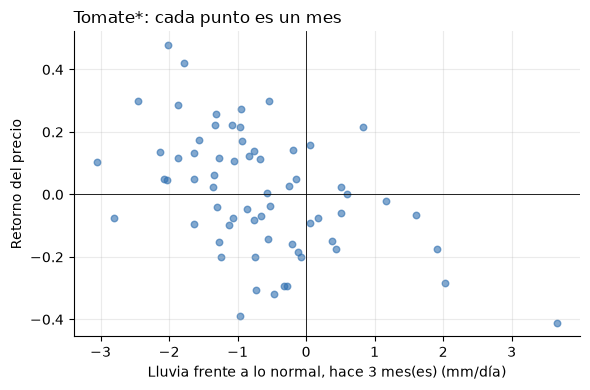

In [16]:
f = correlaciones.loc[correlaciones["spearman"].abs().idxmax()]
lluvia = clima.loc[(clima["producto"] == f["producto_zona"]) & (clima["departamento"] == f["departamento"]),
                   ["periodo", "precipitacion_anomalia"]]
# rezagar(): la lluvia de hace k meses queda con la etiqueta del mes actual
cruce = (ret[ret["producto"] == f["producto"]]
         .merge(vigilancia.rezagar(lluvia, int(f["rezago"])), on="periodo")
         .dropna(subset=["retorno", "precipitacion_anomalia"]))
rho = cruce["retorno"].rank().corr(cruce["precipitacion_anomalia"].rank())
assert np.isclose(round(rho, 3), f["spearman"])
print(f"{f['producto']} vs. lluvia de {f['departamento']} de hace {int(f['rezago'])} mes(es): "
      f"rho = {rho:+.3f} con {len(cruce)} meses. Coincide con la funcion.")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(cruce["precipitacion_anomalia"], cruce["retorno"], color=AZUL, alpha=0.6, s=22)
ax.axhline(0, color="black", lw=0.6); ax.axvline(0, color="black", lw=0.6)
ax.set_xlabel(f"Lluvia frente a lo normal, hace {int(f['rezago'])} mes(es) (mm/día)")
ax.set_ylabel("Retorno del precio")
ax.set_title(f"{f['producto']}: cada punto es un mes", loc="left")
fig.tight_layout()

**¿Habría servido en el pasado?** `vigilancia.acierto_historico()` cuenta cuántas veces la
pista habría acertado la dirección del precio. Tirar una moneda acierta el 50 %.
`vigilancia.senales()` convierte las relaciones fuertes en la lista de vigilancia del mes siguiente.

In [17]:
aciertos = vigilancia.acierto_historico(ret, clima, zonas, correlaciones)
display(aciertos.sort_values("tasa_acierto", ascending=False))

proximo = int((pd.Period(str(ultimo_cerrado), freq="M") + 1).strftime("%Y%m"))
vigilancia.senales(correlaciones, clima, zonas, proximo)[
    ["producto", "departamento", "rezago", "spearman", "periodo_lluvia", "anomalia", "senal"]]

,producto,departamento,rezago,meses,aciertos,tasa_acierto
0,Papa negra*,Cundinamarca,2,65,42,0.646
1,Tomate*,Norte de Santander,3,65,40,0.615


,producto,departamento,rezago,spearman,periodo_lluvia,anomalia,senal
1,Tomate*,Norte de Santander,3,-0.448,202607,-0.556,al alza
0,Papa negra*,Cundinamarca,2,-0.368,202608,-0.301,al alza


**Cómo se lee.** $\rho = -0{,}35$ con rezago 2 dice: "cuando llovió más de lo normal, dos
meses después el precio tendió a bajar". Es una tendencia, no una regla.

**Límites.** (1) **Correlación no es causalidad**: dos cosas pueden moverse juntas sin que
una cause la otra. (2) La tasa de acierto está medida con los mismos meses con que se calculó
$\rho$, así que es optimista. (3) Solo 7 productos tienen zona productora configurada.

---
## 5. Efecto del clima, eslabón por eslabón

**Para qué sirve.** El capítulo 4 mira precio contra lluvia de un salto. Aquí se revisa la
cadena completa, un eslabón a la vez, para ver **dónde** se sostiene y dónde no:

```
El Niño (ONI)  →  lluvia en la zona  →  toneladas que llegan  →  precio
```

| Eslabón | Pregunta | Método |
|---|---|---|
| `oni->lluvia` | ¿El Niño cambia la lluvia de esta zona? | Correlación de Pearson |
| `lluvia->oferta` | ¿La lluvia cambia las toneladas que llegan? | Regresión, descontando la temporada |
| `oferta->precio` | ¿Menos toneladas = precio más alto? | Panel por departamento |
| `lluvia->precio` | Efecto total de la lluvia sobre el precio | Regresión, descontando la temporada |

**Tres ideas para leer la tabla.**

- **Coeficiente**: fuerza y sentido de la relación. Negativo = cuando una sube, la otra baja.
- **p-valor**: probabilidad de ver una relación así de fuerte **por puro azar**. Bajo = es
  difícil que sea casualidad.
- **q-valor**: el p-valor corregido. Si se hacen 100 pruebas, unas 5 salen "significativas"
  solo por suerte; el q-valor descuenta eso. **La regla del proyecto es $q < 0{,}1$.**

**"Descontando la temporada"** significa que cada mes del año recibe su propio nivel. Sin eso,
la lluvia y los precios parecerían relacionados solo porque los dos cambian con las estaciones.

In [18]:
efecto = con.execute("SELECT * FROM resultado_efecto_clima").df()
resumen_efecto = (efecto.assign(se_sostiene=efecto["q_valor"] < 0.1)
                  .groupby("eslabon").agg(pruebas=("q_valor", "size"), se_sostienen=("se_sostiene", "sum")))
resumen_efecto

,pruebas,se_sostienen
eslabon,,
lluvia->oferta,24,0
lluvia->precio,36,1
oferta->precio,24,4
oni->lluvia,56,27


**El q-valor a mano** (`sensibilidad.q_valores()`, método de Benjamini-Hochberg): se ordenan los p-valores y cada uno se multiplica por *cuántas pruebas hay ÷ su posición*.

In [19]:
p = pd.Series([0.001, 0.010, 0.040, 0.200, 0.800], name="p_valor")
tabla_q = p.to_frame()
tabla_q["posicion"] = range(1, len(p) + 1)
tabla_q["p x 5 / posicion"] = p * len(p) / tabla_q["posicion"]
tabla_q["q_valor (funcion)"] = sensibilidad.q_valores(p)
tabla_q

,p_valor,posicion,p x 5 / posicion,q_valor (funcion)
0,0.001,1,0.005,0.005
1,0.010,2,0.025,0.025
2,0.040,3,0.067,0.067
3,0.200,4,0.250,0.250
4,0.800,5,0.800,0.800


**Primer eslabón, reproducido**: ¿El Niño cambia la lluvia? `sensibilidad.oni_lluvia()` correlaciona el índice ONI con la lluvia de cada departamento, probando de 0 a 6 meses de rezago.

Los coeficientes recalculados son los mismos que estan guardados en la base.


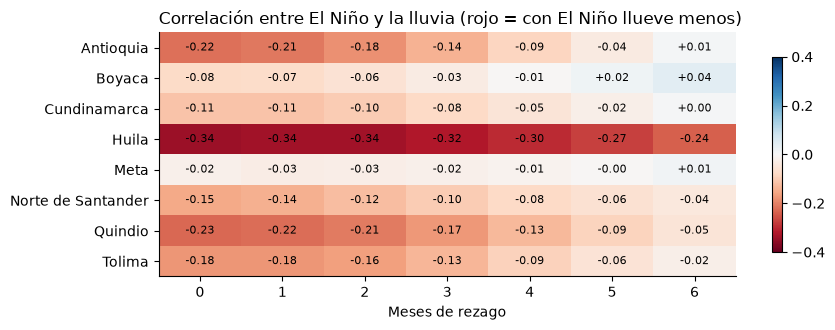

In [20]:
enso = con.execute("SELECT anio, mes, anomalia FROM mundo_fenomeno_nino").df()
clima_depto = con.execute("SELECT departamento, periodo, precipitacion_anomalia FROM mundo_clima_zona_mensual").df()

eslabon_1 = pd.DataFrame(sensibilidad.oni_lluvia(enso, clima_depto))
guardado = efecto[efecto["eslabon"] == "oni->lluvia"].reset_index(drop=True)
assert np.allclose(eslabon_1["coeficiente"], guardado["coeficiente"])
print("Los coeficientes recalculados son los mismos que estan guardados en la base.")

tabla = eslabon_1.pivot(index="departamento", columns="rezago_meses", values="coeficiente")
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(tabla, cmap="RdBu", vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_xticks(range(tabla.shape[1]), tabla.columns); ax.set_yticks(range(tabla.shape[0]), tabla.index)
ax.set_xlabel("Meses de rezago"); ax.grid(False)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        ax.text(j, i, f"{tabla.iloc[i, j]:+.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlación entre El Niño y la lluvia (rojo = con El Niño llueve menos)", loc="left")
fig.colorbar(im, ax=ax, shrink=0.8); fig.tight_layout()

**La regresión a mano** (`sensibilidad.ols()`): mínimos cuadrados, la recta que mejor pasa por
los puntos. Aquí con el eslabón `lluvia->precio` del producto y la zona del capítulo 4:

In [21]:
k = int(f["rezago"])
lluvia_zona = sensibilidad.lluvia_por_zona(clima_depto)
zona = lluvia_zona.loc[lluvia_zona["departamento"] == f["departamento"], ["periodo", "lluvia"]]
cruce = ret.loc[ret["producto"] == f["producto"], ["periodo", "retorno"]].merge(sensibilidad.rezagar(zona, k), on="periodo")

resultado = sensibilidad.ols(cruce["retorno"], cruce[["lluvia"]], efectos={"mes": cruce["periodo"] % 100})
print(f"{f['producto']} vs. lluvia de {f['departamento']} de hace {k} mes(es), descontando la temporada:")
print(f"  coeficiente = {resultado['coeficiente']:+.4f}   p-valor = {resultado['p_valor']:.4f}   meses = {resultado['n']}")

fila = efecto[(efecto["eslabon"] == "lluvia->precio") & (efecto["producto"] == f["producto"])
              & (efecto["departamento"] == f["departamento"]) & (efecto["rezago_meses"] == k)].iloc[0]
assert np.isclose(fila["coeficiente"], resultado["coeficiente"])
print(f"  en la base: coeficiente = {fila['coeficiente']:+.4f}, q-valor = {fila['q_valor']:.3f} -> "
      f"{'se sostiene' if fila['q_valor'] < 0.1 else 'NO se sostiene: puede ser azar'}")

Tomate* vs. lluvia de Norte de Santander de hace 3 mes(es), descontando la temporada:
  coeficiente = -0.0722   p-valor = 0.0002   meses = 65
  en la base: coeficiente = -0.0722, q-valor = 0.006 -> se sostiene


**Cómo se lee.** En `oferta->precio` el coeficiente es una elasticidad: −0,5 quiere decir
"1 % más de toneladas, 0,5 % menos de precio".

**Límites.** (1) Correlación no es causalidad: esto señala pistas. (2) Una relación con
$q \ge 0{,}1$ **no se reporta como hallazgo**, aunque el coeficiente se vea grande.
(3) El p-valor usa la aproximación normal; con 40 meses o más la diferencia es mínima.

---
## 6. Quiebres: ¿el precio cambió de comportamiento?

**Para qué sirve.** Pregunta si, al empezar una fase de El Niño o La Niña, un precio empezó a
comportarse distinto: a subir a otro **ritmo**, o a moverse con otra **volatilidad**.

**La fórmula (prueba de Chow).** Se parte la serie en "antes" y "después" de la fecha y se
compara qué tan bien la describe un solo promedio contra dos promedios separados:

$$F = \frac{SCR_{todo} - (SCR_{antes} + SCR_{después})}{(SCR_{antes} + SCR_{después}) / (n - 2)}$$

- $SCR$: suma de las distancias al promedio, al cuadrado (qué tan mal describe el promedio a los datos).
- Si dos promedios describen **mucho** mejor que uno, $F$ es grande y hay quiebre.
- Para la volatilidad se usa la misma cuenta sobre la distancia de cada dato a la mediana de su
  tramo (prueba de Brown-Forsythe).

**Tres trampas que el código evita** (`src/indicators/quiebres.py` las explica con cifras):

1. **Inflación común.** En 2022-2023 todo subió. Se usa el precio **relativo**: el del
   producto dividido por la mediana de la canasta ese mes (`quiebres.precio_relativo()`).
2. **Inercia.** Un precio alto suele seguir alto, y eso engaña a la prueba. Por eso se prueba
   sobre los **cambios** mensuales, sin temporada (`quiebres.cambios_sin_temporada()`).
3. **Buscar fechas al azar.** Probando todas las fechas siempre aparece un quiebre. Solo se
   prueban los inicios de fase de El Niño/La Niña (`quiebres.inicios_de_fase()`,
   `quiebres.candidatos()`), y se corrige con el q-valor.

In [22]:
nacional = con.execute("SELECT producto, periodo, median(precio_cop_kg) AS precio "
                       "FROM col_precio_mayorista_mensual WHERE mes_cerrado GROUP BY producto, periodo").df()
fases = con.execute("SELECT anio, mes, fase FROM mundo_fenomeno_nino").df()

fechas = quiebres.candidatos(quiebres.inicios_de_fase(fases, int(nacional["periodo"].min())), nacional["periodo"])
print("Fechas que se prueban (inicios de fase con meses suficientes a cada lado):")
display(fechas)

cambios = quiebres.cambios_sin_temporada(nacional)
guardados = con.execute("SELECT * FROM resultado_quiebres").df()
guardados.groupby("que_cambia").agg(pruebas=("hay_quiebre", "size"), quiebres=("hay_quiebre", "sum"))

Fechas que se prueban (inicios de fase con meses suficientes a cada lado):


,periodo,fase
0,202302,Neutral
1,202306,El Nino
2,202405,Neutral


,pruebas,quiebres
que_cambia,,
ritmo,99,0
volatilidad,99,0


**A mano**, con la prueba de ritmo que tiene el resultado más fuerte:

In [23]:
q = guardados[guardados["que_cambia"] == "ritmo"].sort_values("p_valor").iloc[0]
serie = cambios[cambios["producto"] == q["producto"]]
antes = serie.loc[serie["periodo"] < q["periodo_quiebre"], "cambio"]
despues = serie.loc[serie["periodo"] >= q["periodo_quiebre"], "cambio"]
todo = pd.concat([antes, despues])

scr = lambda s: ((s - s.mean()) ** 2).sum()
F = (scr(todo) - (scr(antes) + scr(despues))) / ((scr(antes) + scr(despues)) / (len(todo) - 2))
print(f"{q['producto']}, quiebre en {int(q['periodo_quiebre'])} (empieza {q['fase_que_empieza']})")
print(f"  cambio mensual promedio antes:   {antes.mean() * 100:+.2f} %  ({len(antes)} meses)")
print(f"  cambio mensual promedio despues: {despues.mean() * 100:+.2f} %  ({len(despues)} meses)")
print(f"  SCR con un promedio: {scr(todo):.4f}   SCR con dos: {scr(antes) + scr(despues):.4f}")
print(f"  F = {F:.3f}")

funcion = quiebres.chow_media(antes, despues)
assert np.isclose(F, funcion["f"]) and np.isclose(F, q["f_chow"])
print(f"  quiebres.chow_media() da F = {funcion['f']:.3f}, p = {funcion['p_valor']:.4f}; "
      f"en la base q = {q['q_valor']:.3f} -> hay_quiebre = {bool(q['hay_quiebre'])}")
bf = quiebres.brown_forsythe(antes, despues)
print(f"  quiebres.brown_forsythe() (volatilidad): antes {bf['valor_antes'] * 100:.1f} %, "
      f"despues {bf['valor_despues'] * 100:.1f} %, p = {bf['p_valor']:.3f}")

Cebolla junca, quiebre en 202302 (empieza Neutral)
  cambio mensual promedio antes:   +3.75 %  (21 meses)
  cambio mensual promedio despues: -1.79 %  (44 meses)
  SCR con un promedio: 0.6600   SCR con dos: 0.6164
  F = 4.459
  quiebres.chow_media() da F = 4.459, p = 0.0347; en la base q = 0.987 -> hay_quiebre = False
  quiebres.brown_forsythe() (volatilidad): antes 9.3 %, despues 10.2 %, p = 0.359


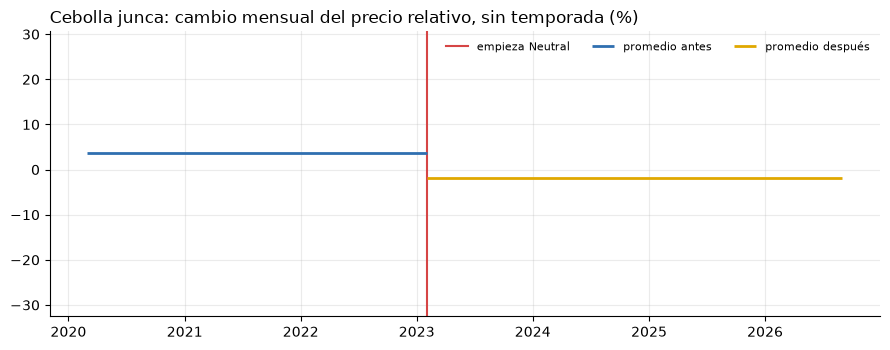

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.6))
corte = fecha([q["periodo_quiebre"]])[0]
ax.bar(fecha(serie["periodo"]), serie["cambio"] * 100, width=20, color=GRIS)
ax.axvline(corte, color=ROJO, lw=1.5, label=f"empieza {q['fase_que_empieza']}")
ax.hlines(antes.mean() * 100, fecha(serie["periodo"]).min(), corte, color=AZUL, lw=2, label="promedio antes")
ax.hlines(despues.mean() * 100, corte, fecha(serie["periodo"]).max(), color=AMARILLO, lw=2, label="promedio después")
ax.set_title(f"{q['producto']}: cambio mensual del precio relativo, sin temporada (%)", loc="left")
ax.legend(frameon=False, fontsize=8, ncol=3); fig.tight_layout()

**Cómo se lee.** `hay_quiebre = True` dice que el cambio se sostiene después de corregir por
todas las pruebas hechas. La tabla de arriba dice cuántas lo logran. Si son cero, la conclusión
honesta es: **con estos datos no hay evidencia de que El Niño o La Niña hayan cambiado el
comportamiento de los precios**. Vistos uno por uno algunos p-valores parecen bajos (como el del
ejemplo), pero al corregir por las 99 pruebas hechas dejan de sostenerse.

**Límite.** Con unos 30 meses a cada lado, la prueba solo detecta cambios grandes.
"No hay evidencia de quiebre" no es lo mismo que "no hubo ningún efecto".

---
## 7. Pronóstico del precio

**Para qué sirve.** Estima el precio nacional de cada producto dentro de 1, 2 y 3 meses.

**El modelo.** Una regresión que pronostica **cuánto va a cambiar** el precio desde hoy, con
lo que ya se sabe hoy:

$$\text{cambio}_{t \to t+h} = \underbrace{a_{\text{mes de destino}}}_{\text{temporada}} + b \cdot \underbrace{\text{inercia}_t}_{\text{cambio del último mes}} + c \cdot \underbrace{\text{ONI}_t}_{\text{El Niño}} + d \cdot \underbrace{\text{lluvia}_t}_{\text{en la zona}}$$

**Los rivales.** Antes de creerle al modelo se compara contra dos pronósticos "ingenuos":

- **Sin cambio:** el precio se queda como está hoy.
- **Estacional:** cambia igual que cambió el año pasado entre esos mismos meses.

**Reglas de honestidad** (están en el encabezado de `src/indicators/pronostico.py`):

1. **Prueba sin trampa (backtest).** Para cada uno de los últimos 24 meses, se entrena solo
   con lo que se sabía ese mes y se pronostica el siguiente. Luego se mide el error real.
2. **Si el modelo no le gana al mejor ingenuo por al menos 5 %, se presenta el ingenuo** y se dice.
3. **La banda** (80 %) sale de los errores reales del backtest, no de una fórmula teórica.

In [25]:
# La serie de un producto, armada igual que en pronostico.construir()
oni = con.execute("SELECT anio * 100 + mes AS periodo, anomalia AS oni FROM mundo_fenomeno_nino").df()
lluvia_prod = con.execute(
    "SELECT z.producto_sipsa AS producto, c.periodo, avg(c.precipitacion_anomalia) AS lluvia "
    "FROM catalogo_zona_productora z JOIN mundo_clima_zona_mensual c "
    "ON c.producto = z.producto_zona AND c.departamento = z.departamento "
    "WHERE z.producto_sipsa IS NOT NULL GROUP BY 1, 2").df()

def serie_de(producto):
    s = nacional[nacional["producto"] == producto].assign(log_precio=lambda d: np.log(d["precio"]))
    return (s.merge(oni, on="periodo", how="left")
             .merge(lluvia_prod[lluvia_prod["producto"] == producto].drop(columns="producto"), on="periodo", how="left")
             .sort_values("periodo"))

PRODUCTO_P = "Papa negra*"
serie_p = serie_de(PRODUCTO_P)
print("Las filas con que se entrena (pronostico.armar_filas, horizonte de 1 mes):")
pronostico.armar_filas(serie_p, 1).tail(5)

Las filas con que se entrena (pronostico.armar_filas, horizonte de 1 mes):


,origen,destino,log_hoy,cambio,inercia,oni,lluvia,estacional
60,202604,202605,7.394,0.036,0.004,0.460,-0.338,-0.152
61,202605,202606,7.430,0.185,0.036,0.950,0.880,-0.471
62,202606,202607,7.615,-0.064,0.185,1.390,1.351,-0.681
63,202607,202608,7.551,0.114,-0.064,1.800,1.736,-0.827
64,202608,202609,7.665,0.143,0.114,2.160,0.084,-0.929


Cada fila es un mes de **origen** y su **destino**. `cambio` es lo que hay que adivinar;
`inercia`, `oni` y `lluvia` es lo que se sabía en el origen; `estacional` es lo que diría el
rival estacional.

**El backtest** (`pronostico.backtest()` y `pronostico.evaluar()`): ¿qué habría dicho cada uno, y cuánto se equivocó?

In [26]:
ev = pronostico.evaluar(serie_p, 1)
bt = ev["backtest"]
a_pesos = bt.assign(real=np.exp(bt["real_log"]), modelo=np.exp(bt["pronostico_log"]),
                    sin_cambio=np.exp(bt["sin_cambio_log"]), estacional=np.exp(bt["estacional_log"]))
display(a_pesos[["origen", "destino", "real", "modelo", "sin_cambio", "estacional"]].tail(6))

# El error a mano: diferencia de logaritmos x 100 es, aproximadamente, el error en %
error_mano = (bt["real_log"] - bt["pronostico_log"]).abs().mean() * 100
assert np.isclose(error_mano, ev["mae_modelo"])
print(f"Error promedio en {len(bt)} meses de prueba ({PRODUCTO_P}, a 1 mes):")
print(f"  modelo:     {ev['mae_modelo']:.1f} %")
print(f"  sin cambio: {ev['mae_sin_cambio']:.1f} %")
print(f"  estacional: {ev['mae_estacional']:.1f} %")

,origen,destino,real,modelo,sin_cambio,estacional
18,202603,202604,"1,626.725","1,497.947","1,620.575","1,893.025"
19,202604,202605,"1,685.665","1,520.586","1,626.725","1,397.100"
20,202605,202606,"2,028.765","1,709.910","1,685.665","1,052.925"
21,202606,202607,"1,903.145","2,156.984","2,028.765","1,026.950"
22,202607,202608,"2,133.415","1,711.863","1,903.145",832.100
23,202608,202609,"2,461.440","2,431.487","2,133.415",842.365


Error promedio en 24 meses de prueba (Papa negra*, a 1 mes):
  modelo:     14.4 %
  sin cambio: 12.1 %
  estacional: 47.1 %


In [27]:
futuro = pronostico.pronosticar(serie_p)
display(futuro)

guardado = con.execute("SELECT * FROM resultado_pronostico_precio WHERE producto = ? AND tipo = 'pronostico' "
                       "ORDER BY horizonte", [PRODUCTO_P]).df()
assert np.allclose(futuro["valor"], guardado["valor"])
print("El pronostico recalculado es el mismo que esta guardado en la base.")

,periodo,horizonte,valor,lim_inf,lim_sup,modelo,mae_modelo,mae_ingenuo,gana_al_ingenuo
0,202610,1,"2,461.440","1,928.610","3,043.078",sin_cambio,14.415,12.102,False
1,202611,2,"2,461.440","1,822.306","3,259.197",sin_cambio,23.552,21.253,False
2,202612,3,"2,461.440","1,417.017","3,476.556",sin_cambio,34.922,28.477,False


El pronostico recalculado es el mismo que esta guardado en la base.


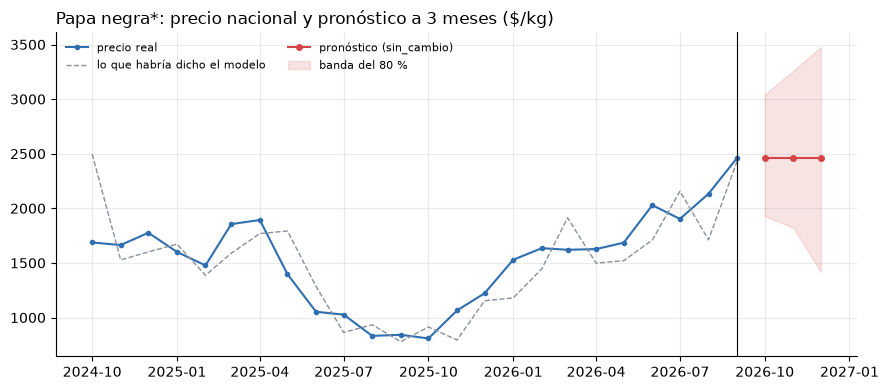

In [28]:
reciente = serie_p.tail(24)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fecha(reciente["periodo"]), reciente["precio"], color=AZUL, marker="o", ms=3, label="precio real")
ax.plot(fecha(a_pesos["destino"]), a_pesos["modelo"], color=GRIS, ls="--", lw=1, label="lo que habría dicho el modelo")
x_fut = fecha(futuro["periodo"])
ax.plot(x_fut, futuro["valor"], color=ROJO, marker="o", ms=4, label=f"pronóstico ({futuro['modelo'].iloc[0]})")
ax.fill_between(x_fut, futuro["lim_inf"], futuro["lim_sup"], color=ROJO, alpha=0.15, label="banda del 80 %")
ax.axvline(fecha([reciente["periodo"].iloc[-1]])[0], color="black", lw=0.8)
ax.set_title(f"{PRODUCTO_P}: precio nacional y pronóstico a 3 meses ($/kg)", loc="left")
ax.legend(frameon=False, fontsize=8, ncol=2); fig.tight_layout()

**El marcador completo**: ¿en cuántos productos el modelo le gana al ingenuo?

In [29]:
todos = con.execute("SELECT * FROM resultado_pronostico_precio WHERE tipo = 'pronostico'").df()
marcador = (todos.groupby("horizonte")
            .agg(productos=("producto", "nunique"), gana_el_modelo=("gana_al_ingenuo", "sum"),
                 error_modelo_pct=("mae_modelo", "median"), error_ingenuo_pct=("mae_ingenuo", "median")))
marcador["gana_el_modelo"] = marcador["gana_el_modelo"].astype(int)
display(marcador)
print("Que metodo se presenta en cada caso:")
print(todos.groupby(["horizonte", "modelo"]).size().unstack(fill_value=0).to_string())

,productos,gana_el_modelo,error_modelo_pct,error_ingenuo_pct
horizonte,,,,
1.000,33,11,10.050,10.502
2.000,33,8,16.165,15.907
3.000,33,4,19.260,18.335


Que metodo se presenta en cada caso:
modelo     estacional  regresion  sin_cambio
horizonte                                   
1.000               2         11          20
2.000               7          8          18
3.000              13          4          16


**Cómo se lee.** `gana_el_modelo` es el número de productos donde la regresión se equivoca al
menos 5 % menos que el mejor ingenuo. En los demás, lo que se muestra es el ingenuo.

**Límites, y hay que decirlos en la sustentación.**

- En la mayoría de los productos **el modelo no le gana a suponer que el precio sigue igual**.
  Es un resultado, no un defecto escondido: los precios agrícolas de un mes al otro son
  difíciles de anticipar, y el proyecto lo mide en vez de prometer.
- El pronóstico es del precio **nacional** (mediana de los mercados), no de cada ciudad.
- La banda del 80 % quiere decir que, en el pasado, 8 de cada 10 veces el precio real cayó dentro.
- No se cruza el hueco de 2021: un destino al otro lado del hueco no entra al entrenamiento.

---
## 8. Dependencia de importaciones

**Para qué sirve.** Dice qué parte de lo que consume el país viene de afuera. Si es alta, el
precio interno queda expuesto al dólar y al precio internacional.

**La fórmula.**

$$\text{dependencia} = \frac{\text{importaciones}}{\text{producción} + \text{importaciones} - \text{exportaciones}} \times 100$$

El denominador es el **consumo aparente**: lo que se produjo, más lo que entró, menos lo que salió.
Los datos son de FAOSTAT (`mundo_fao_colombia`, dominios `produccion` y `comercio`), en toneladas.

A mano, Chick peas, dry en 2024: 13,338 / (5 + 13,338 - 1) x 100 = 100.0 %


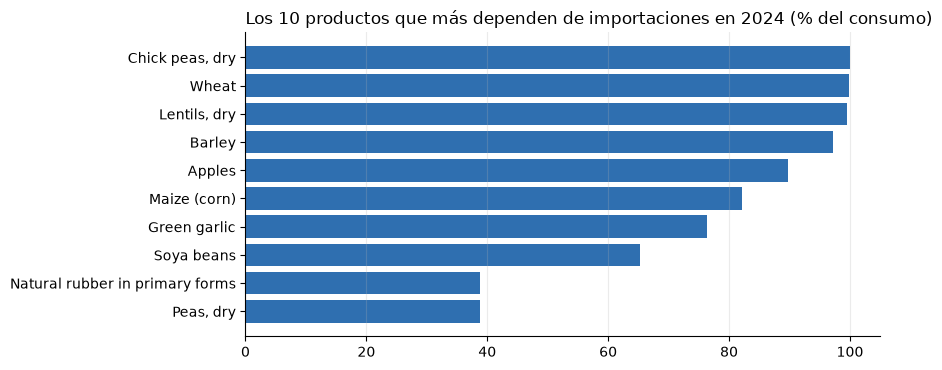

In [30]:
comercio = con.execute("SELECT * FROM mundo_fao_colombia WHERE dominio = 'comercio'").df()
produccion = con.execute("SELECT * FROM mundo_fao_colombia WHERE dominio = 'produccion'").df()
nombres = con.execute("SELECT item_codigo, any_value(item) AS item FROM mundo_fao_colombia GROUP BY 1").df()

dep = volatilidad.dependencia_importaciones(comercio, produccion).merge(nombres, on="item_codigo")
anio = int(dep["anio"].max())
# Solo productos que el pais tambien produce y consume en cantidad (mas de 1.000 t)
del_anio = dep[(dep["anio"] == anio) & (dep["produccion"] > 0) & (dep["consumo_aparente"] > 1000)
               & dep["dependencia_pct"].between(0, 100)]
top = del_anio.nlargest(10, "dependencia_pct")

uno = top.iloc[0]
a_mano = 100 * uno["importacion"] / (uno["produccion"] + uno["importacion"] - uno["exportacion"])
assert np.isclose(round(a_mano, 2), uno["dependencia_pct"])
print(f"A mano, {uno['item']} en {anio}: {uno['importacion']:,.0f} / ({uno['produccion']:,.0f} + "
      f"{uno['importacion']:,.0f} - {uno['exportacion']:,.0f}) x 100 = {a_mano:.1f} %")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(top["item"].str.slice(0, 45)[::-1], top["dependencia_pct"][::-1], color=AZUL)
ax.set_title(f"Los 10 productos que más dependen de importaciones en {anio} (% del consumo)", loc="left")
ax.grid(axis="y", visible=False); fig.tight_layout()

**Límite.** Los datos de la FAO son anuales y llegan con uno o dos años de rezago: sirven de
contexto, no de alerta. Los nombres van en inglés, como los publica la FAO.

---
## 9. De dónde sale cada cifra reportada

Cada número que usamos en el informe y en la presentación, recalculado aquí con los datos de hoy.
Si la base se actualiza, estas cifras pueden moverse: **la que vale es la que imprime esta celda.**

In [31]:
limon = resumen.loc[resumen["producto"] == "Limón Tahití", "volatilidad_mediana"].iloc[0] * 100
bog = precios[(precios["producto"] == "Limón Tahití") & (precios["mercado"] == "BOGOTÁ, D.C.")]
p_max, p_min = bog.loc[bog["precio_cop_kg"].idxmax()], bog.loc[bog["precio_cop_kg"].idxmin()]

meses_por_serie = precios.groupby(["mercado", "producto"])["periodo"].nunique()
catalogo = con.execute("SELECT * FROM catalogo_producto").df()
estables = resumen.nsmallest(2, "volatilidad_mediana")
h1 = marcador.loc[1.0]

cifras = pd.DataFrame([
    ("Volatilidad anualizada mediana del limón Tahití", f"{limon:.1f} %", "Capítulo 2, resumen_por_producto()"),
    ("Precio máximo del limón Tahití en Bogotá", f"{p_max['precio_cop_kg']:,.2f} $/kg ({int(p_max['periodo'])})", "Capítulo 1, tabla de precios"),
    ("Precio mínimo del limón Tahití en Bogotá", f"{p_min['precio_cop_kg']:,.2f} $/kg ({int(p_min['periodo'])})", "Capítulo 1, tabla de precios"),
    ("Cuántas veces cabe el mínimo en el máximo", f"{p_max['precio_cop_kg'] / p_min['precio_cop_kg']:.1f} veces", "Capítulo 1"),
    ("Productos más estables", ", ".join(f"{r.producto} ({r.volatilidad_mediana * 100:.0f} %)" for r in estables.itertuples()), "Capítulo 2"),
    ("Series producto-mercado", f"{len(meses_por_serie)}", "Capítulo 1, tabla de precios"),
    ("Series con 24 meses o más de historia", f"{(meses_por_serie >= 24).mean() * 100:.0f} %", "Capítulo 1, tabla de precios"),
    ("Productos comparables con la FAO (correspondencia exacta)", f"{int(catalogo['permite_comparar_precio'].sum())} de {len(catalogo)}", "catalogo_producto"),
    ("Alertas rojas y amarillas en el último mes cerrado", f"{(hoy['alerta'] == 'roja').sum()} rojas, {(hoy['alerta'] == 'amarilla').sum()} amarillas ({ultimo_cerrado})", "Capítulo 3"),
    ("Relaciones clima-precio que se sostienen (q < 0,1)", f"{int((efecto['q_valor'] < 0.1).sum())} de {len(efecto)}", "Capítulo 5"),
    ("Quiebres que se sostienen", f"{int(guardados['hay_quiebre'].sum())} de {len(guardados)}", "Capítulo 6"),
    ("Productos donde el modelo le gana al ingenuo (a 1 mes)", f"{int(h1['gana_el_modelo'])} de {int(h1['productos'])}", "Capítulo 7"),
], columns=["Cifra", "Valor hoy", "Dónde se calcula"])
pd.set_option("display.max_colwidth", None)
cifras

,Cifra,Valor hoy,Dónde se calcula
0,Volatilidad anualizada mediana del limón Tahití,135.2 %,"Capítulo 2, resumen_por_producto()"
1,Precio máximo del limón Tahití en Bogotá,"6,074.83 $/kg (202303)","Capítulo 1, tabla de precios"
2,Precio mínimo del limón Tahití en Bogotá,698.09 $/kg (202306),"Capítulo 1, tabla de precios"
3,Cuántas veces cabe el mínimo en el máximo,8.7 veces,Capítulo 1
4,Productos más estables,"Coco (24 %), Banano* (25 %)",Capítulo 2
5,Series producto-mercado,559,"Capítulo 1, tabla de precios"
6,Series con 24 meses o más de historia,93 %,"Capítulo 1, tabla de precios"
7,Productos comparables con la FAO (correspondencia exacta),13 de 33,catalogo_producto
8,Alertas rojas y amarillas en el último mes cerrado,"2 rojas, 9 amarillas (202609)",Capítulo 3
9,"Relaciones clima-precio que se sostienen (q < 0,1)",32 de 140,Capítulo 5


---
## 10. Comprobación: el cuaderno reproduce la base

Las tres tablas de resultados de la base (`resultado_...`) las escribe `scripts/integrar.py`
llamando a las mismas funciones que usa este cuaderno. Aquí se recalculan completas y se
comparan con lo guardado. Si alguna no coincide, la celda falla.

In [32]:
def iguales(recalculada, tabla, llaves):
    guardada = con.execute(f"SELECT * FROM {tabla}").df()
    a = recalculada.sort_values(llaves).reset_index(drop=True)
    b = guardada.sort_values(llaves).reset_index(drop=True)[a.columns]
    pd.testing.assert_frame_equal(a, b, check_dtype=False, check_exact=False, rtol=1e-9)
    print(f"OK  {tabla:30} {len(a):>6,} filas identicas")

iguales(sensibilidad.construir(con), "resultado_efecto_clima",
        ["eslabon", "departamento", "producto", "rezago_meses"])
iguales(quiebres.construir(con), "resultado_quiebres",
        ["producto", "periodo_quiebre", "que_cambia"])
iguales(pronostico.construir(con), "resultado_pronostico_precio",
        ["producto", "tipo", "periodo", "horizonte"])

OK  resultado_efecto_clima            140 filas identicas


OK  resultado_quiebres                198 filas identicas


OK  resultado_pronostico_precio     3,102 filas identicas


### Índice de funciones

Todas las funciones públicas de `src/indicators/`, con el archivo y la línea donde están.

In [33]:
import inspect

filas = []
for modulo in (volatilidad, vigilancia, sensibilidad, quiebres, pronostico):
    for nombre, funcion in inspect.getmembers(modulo, inspect.isfunction):
        if funcion.__module__ != modulo.__name__ or nombre.startswith("_"):
            continue
        linea = inspect.getsourcelines(funcion)[1]
        resumen_doc = (inspect.getdoc(funcion) or "").split("\n")[0]
        filas.append((f"{modulo.__name__.split('.')[-1]}.{nombre}()",
                      f"src/indicators/{modulo.__name__.split('.')[-1]}.py:{linea}", resumen_doc))
con.close()
pd.DataFrame(filas, columns=["Función", "Dónde está", "Qué hace"])

,Función,Dónde está,Qué hace
0,volatilidad.alertas(),src/indicators/volatilidad.py:74,"Clasifica cada mes en verde, amarilla o roja segun el z-score del retorno."
1,volatilidad.dependencia_importaciones(),src/indicators/volatilidad.py:125,"imp / (prod + imp - exp) * 100, por item y anio, solo en toneladas."
2,volatilidad.resumen_por_producto(),src/indicators/volatilidad.py:106,Una fila por producto con su volatilidad tipica y sus alertas historicas.
3,volatilidad.retornos(),src/indicators/volatilidad.py:33,Agrega el retorno logaritmico mes a mes de cada serie.
4,volatilidad.volatilidad(),src/indicators/volatilidad.py:61,Agrega la desviacion estandar movil del retorno logaritmico.
5,vigilancia.acierto_historico(),src/indicators/vigilancia.py:128,Que tan seguido la senal habria acertado la direccion del precio en el pasado.
6,vigilancia.correlacion_lluvia(),src/indicators/vigilancia.py:84,Atajo: retorno de cada producto contra la lluvia de SU zona productora.
7,vigilancia.correlacion_rezagada(),src/indicators/vigilancia.py:64,Spearman entre el retorno del mes t y `columna` del mes t-k.
8,vigilancia.retornos_nacionales(),src/indicators/vigilancia.py:31,"Mediana nacional del precio por producto y mes, y su retorno logaritmico."
9,vigilancia.rezagar(),src/indicators/vigilancia.py:53,Corre `periodo` k meses hacia adelante: el dato de t-k queda etiquetado en t.
